# Decision Tree Classifier — UCI Iris Dataset

This notebook downloads the **Iris** dataset directly from the [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/53/iris), trains a Decision Tree classifier, and evaluates it with a held-out test set and stratified 5-fold cross-validation.

**Included evaluation:** accuracy, balanced accuracy, macro/weighted precision, recall and F1, multiclass ROC-AUC, log loss, multiclass Brier score, Matthews correlation coefficient, Cohen’s kappa, per-class specificity, classification report, confusion matrix, and feature importance.

Run the cells **from top to bottom**. An internet connection is required to download the dataset.

## 1. Install dependencies

Run this cell if the required packages are not already installed in your environment. In Jupyter, `%pip` installs packages into the active kernel.

In [ ]:
%pip install -q pandas numpy scikit-learn matplotlib

## 2. Import libraries and set configuration

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    cohen_kappa_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    log_loss,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)

In [2]:
DATA_URL = "https://archive.ics.uci.edu/static/public/53/data.csv"
RANDOM_STATE = 42
TARGET = "class"

## 3. Download and prepare the dataset

The target column is `class`; the remaining columns are used as numerical input features. Any rows with missing target or feature values are excluded.

In [5]:
# TODO
df = pd.read_csv(DATA_URL)
df.head()

,sepal length,sepal width,petal length,petal width,class
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [ ]:
len(df)

150

In [11]:
df.shape

(150, 5)

In [6]:
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)

if TARGET not in df.columns:
    raise ValueError(
        f"Expected target column '{TARGET}'. Found columns: {df.columns.tolist()}"
    )

In [7]:
df.columns.tolist()

['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'class']

In [12]:
# TODO
df = df.dropna(subset=[TARGET]).copy()
y = df[TARGET]
X = df.drop(columns=[TARGET])

In [14]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,class
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [15]:
valid_rows = X.notna().all(axis=1) & y.notna()
X = X.loc[valid_rows]
y = y.loc[valid_rows]

In [16]:
print(f"Dataset URL: {DATA_URL}")
print(f"Number of rows: {len(X)}")
print(f"Number of features: {X.shape[1]}")
print("\nClass distribution:")
display(y.value_counts().sort_index().rename("count").to_frame())

display(X.head())

Dataset URL: https://archive.ics.uci.edu/static/public/53/data.csv
Number of rows: 150
Number of features: 4

Class distribution:


,count
class,
Iris-setosa,50
Iris-versicolor,50
Iris-virginica,50


,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


## 4. Split into training and test sets

A stratified 80/20 split preserves approximately the same class distribution in both sets. The test set is held out until final evaluation.

In [18]:
# TODO
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

print(f"Training samples: {len(X_train)}")
print(f"Test samples: {len(X_test)}")

Training samples: 105
Test samples: 45


## 5. Define the Decision Tree and run 5-fold cross-validation

The model uses the Gini impurity criterion. Feature scaling is not required for a Decision Tree. Cross-validation is performed only on the training split to avoid leaking test information.

In [20]:
# TODO
model = DecisionTreeClassifier(
    criterion="gini",
    random_state=RANDOM_STATE
)

In [21]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

In [22]:
scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro",
    "f1_weighted": "f1_weighted",
}

In [23]:
cv_results = cross_validate(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=False,
    n_jobs=-1,
)

In [24]:
cv_summary = pd.DataFrame(
    {
        "mean": [cv_results[f"test_{name}"].mean() for name in scoring],
        "std_dev": [cv_results[f"test_{name}"].std(ddof=1) for name in scoring],
    },
    index=list(scoring.keys()),
)

display(cv_summary.style.format("{:.4f}"))

,mean,std_dev
accuracy,0.9333,0.0261
balanced_accuracy,0.9333,0.0261
precision_macro,0.9411,0.0247
recall_macro,0.9333,0.0261
f1_macro,0.9328,0.0265
f1_weighted,0.9328,0.0265


## 6. Train the final model and calculate overall test metrics

For most metrics, higher values are better. **Log loss** and **Brier score** are error measures, so lower values are better.

In [25]:
# TODO
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [26]:
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)
classes = model.classes_

In [27]:
# Multiclass Brier score: mean sum of squared probability errors per sample.
y_onehot = (
    pd.get_dummies(y_test)
    .reindex(columns=classes, fill_value=0)
    .to_numpy()
)
brier_score = np.mean(np.sum((y_proba - y_onehot) ** 2, axis=1))

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Balanced accuracy": balanced_accuracy_score(y_test, y_pred),
    "Precision (macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
    "Recall / sensitivity (macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
    "F1-score (macro)": f1_score(y_test, y_pred, average="macro", zero_division=0),
    "Precision (weighted)": precision_score(y_test, y_pred, average="weighted", zero_division=0),
    "Recall (weighted)": recall_score(y_test, y_pred, average="weighted", zero_division=0),
    "F1-score (weighted)": f1_score(y_test, y_pred, average="weighted", zero_division=0),
    "ROC-AUC (macro, one-vs-rest)": roc_auc_score(
        y_test, y_proba, labels=classes, multi_class="ovr", average="macro"
    ),
    "Log loss": log_loss(y_test, y_proba, labels=classes),
    "Multiclass Brier score": brier_score,
    "Matthews correlation coefficient": matthews_corrcoef(y_test, y_pred),
    "Cohen's kappa": cohen_kappa_score(y_test, y_pred),
}

metrics_df = pd.DataFrame(
    {"metric": list(metrics.keys()), "value": list(metrics.values())}
)
display(metrics_df.style.format({"value": "{:.4f}"}))

print(f"Tree depth: {model.get_depth()}")
print(f"Number of leaves: {model.get_n_leaves()}")

,metric,value
0,Accuracy,0.9333
1,Balanced accuracy,0.9333
2,Precision (macro),0.9444
3,Recall / sensitivity (macro),0.9333
4,F1-score (macro),0.9327
5,Precision (weighted),0.9444
6,Recall (weighted),0.9333
7,F1-score (weighted),0.9327
8,"ROC-AUC (macro, one-vs-rest)",0.9500
9,Log loss,2.4029


Tree depth: 5
Number of leaves: 8


## 7. Classification report, per-class specificity, and confusion matrix

Specificity is calculated one-vs-rest for each class: **TN / (TN + FP)**. In the confusion matrix, rows represent actual classes and columns represent predicted classes.

In [28]:
print("Classification report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=classes,
        digits=4,
        zero_division=0,
    )
)

cm = confusion_matrix(y_test, y_pred, labels=classes)

tp = np.diag(cm).astype(float)
fn = cm.sum(axis=1) - tp
fp = cm.sum(axis=0) - tp
tn = cm.sum() - tp - fn - fp
specificity = np.divide(
    tn,
    tn + fp,
    out=np.zeros_like(tn),
    where=(tn + fp) != 0,
)

per_class_metrics = pd.DataFrame(
    {
        "class": classes,
        "precision": precision_score(
            y_test, y_pred, labels=classes, average=None, zero_division=0
        ),
        "recall_sensitivity": recall_score(
            y_test, y_pred, labels=classes, average=None, zero_division=0
        ),
        "specificity": specificity,
        "f1_score": f1_score(
            y_test, y_pred, labels=classes, average=None, zero_division=0
        ),
        "support": cm.sum(axis=1).astype(int),
    }
)

display(per_class_metrics.style.format({
    "precision": "{:.4f}",
    "recall_sensitivity": "{:.4f}",
    "specificity": "{:.4f}",
    "f1_score": "{:.4f}",
}))

confusion_df = pd.DataFrame(cm, index=classes, columns=classes)
confusion_df.index.name = "Actual / Predicted"
display(confusion_df)

Classification report:
                 precision    recall  f1-score   support

    Iris-setosa     1.0000    1.0000    1.0000        15
Iris-versicolor     1.0000    0.8000    0.8889        15
 Iris-virginica     0.8333    1.0000    0.9091        15

       accuracy                         0.9333        45
      macro avg     0.9444    0.9333    0.9327        45
   weighted avg     0.9444    0.9333    0.9327        45



,class,precision,recall_sensitivity,specificity,f1_score,support
0,Iris-setosa,1.0000,1.0000,1.0000,1.0000,15
1,Iris-versicolor,1.0000,0.8000,1.0000,0.8889,15
2,Iris-virginica,0.8333,1.0000,0.9000,0.9091,15


,Iris-setosa,Iris-versicolor,Iris-virginica
Actual / Predicted,,,
Iris-setosa,15,0,0
Iris-versicolor,0,12,3
Iris-virginica,0,0,15


## 8. Feature importance

Feature importance reflects each feature's contribution to reducing impurity in this fitted tree. It is useful for interpretation, but should not be treated as proof of causation.

,importance
petal_length,0.5412
petal_width,0.4303
sepal_width,0.0286
sepal_length,0.0000


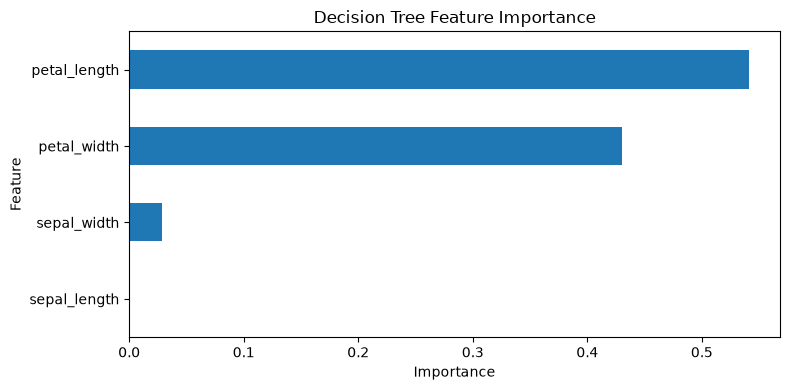

In [29]:
feature_importance = pd.Series(
    model.feature_importances_,
    index=X.columns,
    name="importance",
).sort_values(ascending=False)

display(feature_importance.to_frame().style.format("{:.4f}"))

ax = feature_importance.sort_values().plot(kind="barh", figsize=(8, 4))
ax.set_title("Decision Tree Feature Importance")
ax.set_xlabel("Importance")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()

## 9. Visualize the trained decision tree and confusion matrix

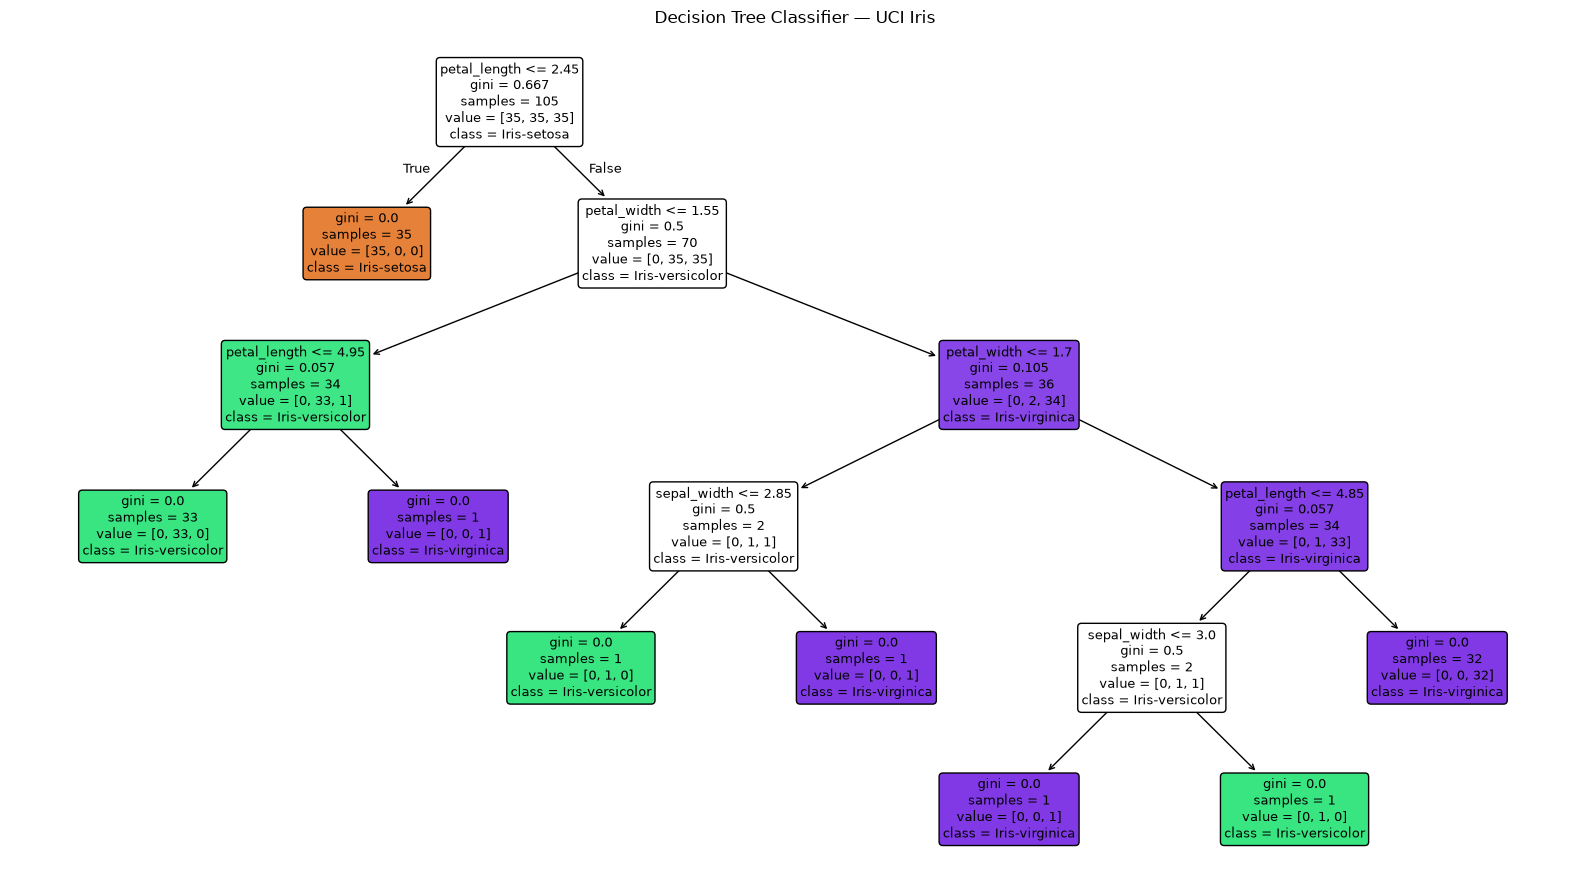

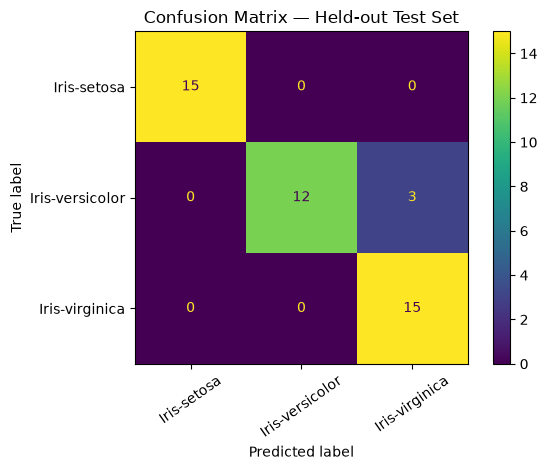

In [30]:
plt.figure(figsize=(16, 9))
plot_tree(
    model,
    feature_names=X.columns.tolist(),
    class_names=classes.tolist(),
    filled=True,
    rounded=True,
    fontsize=9,
)
plt.title("Decision Tree Classifier — UCI Iris")
plt.tight_layout()
plt.show()

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes,
).plot(values_format="d", xticks_rotation=35)
plt.title("Confusion Matrix — Held-out Test Set")
plt.tight_layout()
plt.show()

## Metric interpretation

- **Accuracy:** fraction of all predictions that are correct.
- **Precision:** of the samples predicted as a class, the fraction that truly belong to it.
- **Recall / sensitivity:** of the samples belonging to a class, the fraction correctly identified.
- **Specificity:** of the samples outside a class, the fraction correctly rejected as that class.
- **F1-score:** harmonic mean of precision and recall.
- **Balanced accuracy:** mean recall across classes; less affected by class imbalance than raw accuracy.
- **ROC-AUC:** ability to rank a true class above other classes using predicted probabilities; reported here as macro one-vs-rest.
- **Log loss / Brier score:** probability prediction errors; lower values are better.
- **Matthews correlation coefficient / Cohen’s kappa:** summary measures that account for both correct and incorrect predictions.
- **Cross-validation mean ± standard deviation:** average training-fold performance and variation across folds.